# 04 — YOLO11

YOLO11 (COCO-pretrained), protocol P0.

| run | change | search range |
|---|---|---|
| `yolo-e0` | baseline, imgsz 1280 | — |
| `yolo-e1` | imgsz 1600 | imgsz ∈ {1280, 1600} |
| `yolo-e2` | CIoU + NWD box loss (λ=0.5, C=24 px) | — |
| `yolo11m-e3` | YOLO11m @1600, `k=2`, copy-paste 0.25, mixup 0.15, 2 GPU-h | model size s → m |
| `yolo11s-p2` | + P2 head (first attempt, ensemble member; ablation in 04b) | — |

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
AUG = dict(hflip=0.5, vflip=0.0, degrees=0.0, scale_min=0.5, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3)
INF = dict(conf_thresh=0.001, nms_iou=0.6, max_det=500, slim_conf_thresh=0.05)

## 1. Baseline and experiments A / B

In [3]:
YOLO_E0 = dict(run_id="yolo-e0", family="yolo", exp="e0",
    hypothesis="Anchor-free YOLO11s baseline under Protocol P0 (k=5, imgsz=1280, 1.5 GPU-h budget).",
    model="yolo11s.pt", cache="k5_drop_L1920", imgsz=1280, batch=4, epochs=50, time_budget_h=1.5,
    close_mosaic=2, workers=4, auto_eval_val=True)
YOLO_E1 = dict(run_id="yolo-e1", family="yolo", exp="e1", parent_run="yolo-e0", seed=42,
    hypothesis="Increasing input resolution from 1280 to 1600 increases small-object feature map density and boosts AP_small and overall AP.",
    cache="k5_drop_L1920", k=5, model="yolo11s.pt", imgsz=1600, batch=2, epochs=30, time_budget_h=1.5,
    close_mosaic=2, workers=4, augmentation=AUG, inference=INF)
YOLO_E2 = dict(run_id="yolo-e2", family="yolo", exp="e2", parent_run="yolo-e0", seed=42,
    hypothesis="Blending CIoU with Normalized Wasserstein Distance (lambda_nwd=0.5, C=24.0 px) stabilizes regression gradients for tiny objects (<32^2 px).",
    cache="k5_drop_L1920", k=5, model="yolo11s.pt", imgsz=1280, batch=2, epochs=30, time_budget_h=1.5,
    close_mosaic=2, workers=4, loss_type="ciou_nwd", lambda_nwd=0.5, nwd_c=24.0, augmentation=AUG, inference=INF)

train_ultralytics_run(YOLO_E0, predict_test=True, test_batch=4)
train_ultralytics_run(YOLO_E1, benchmark_imgsz=1600, predict_test=True, test_batch=2)
train_ultralytics_run(YOLO_E2, predict_test=True, test_batch=4)

[yolo-e0] training completed earlier (yolo-e0_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.11215,0.00028,3.87591,1.62207,1.14816,0.19913,0.40701,0.0
1,2,0.20126,0.00052,3.58328,1.54311,0.96211,0.20001,0.41042,0.0
2,3,0.29013,0.00072,3.46894,1.50457,0.90285,0.20429,0.41640,0.0
3,4,0.37913,0.00068,3.39283,1.47833,0.86110,0.19795,0.40385,0.0
4,5,0.47043,0.00063,3.32036,1.44793,0.82795,0.20879,0.41814,0.0
5,6,0.56041,0.00058,3.24046,1.41746,0.79107,0.21181,0.42203,0.0
6,7,0.64974,0.00054,3.19172,1.39935,0.76463,0.21974,0.44444,0.0
7,8,0.73994,0.00049,3.13589,1.37548,0.74569,0.19818,0.39993,0.0
8,9,0.83184,0.00044,3.08090,1.35158,0.72087,0.19870,0.40585,0.0
9,10,1.06059,0.00040,3.03420,1.33085,0.70179,0.19566,0.39477,0.0


[yolo-e0] submission /home/marko/ucu-ai-hw-2/submissions/yolo-e0.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1131619, 'mean_dets_per_frame': 296.93}
[yolo-e0] AP=0.2067 | AP50=0.4156 | APs=0.1085 | AR500=0.3291 | epochs=15 | gpu_h=1.5038 | fps=55.73
[yolo-e1] training completed earlier (yolo-e1_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.15063,0.00028,4.00835,1.63643,1.19050,0.20253,0.40563,0.0
1,2,0.29578,0.00050,3.72964,1.56146,1.01281,0.22298,0.44436,0.0
2,3,0.44129,0.00068,3.62779,1.52755,0.96075,0.21100,0.43173,0.0
3,4,0.58744,0.00061,3.50707,1.48863,0.89485,0.21032,0.41641,0.0
4,5,0.73118,0.00053,3.41774,1.45239,0.85292,0.21214,0.42281,0.0
5,6,0.87723,0.00046,3.34175,1.42817,0.81478,0.22150,0.43400,0.0
6,7,1.02233,0.00038,3.25535,1.39505,0.77623,0.21229,0.42122,0.0
7,8,1.17101,0.00031,3.18983,1.36877,0.74676,0.21658,0.43182,0.0
8,9,1.32044,0.00023,3.13527,1.34329,0.72517,0.20225,0.40963,0.0
9,10,1.45975,0.00016,3.06933,1.31794,0.68873,0.21323,0.42510,0.0


[yolo-e1] submission /home/marko/ucu-ai-hw-2/submissions/yolo-e1.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1260219, 'mean_dets_per_frame': 330.68}
[yolo-e1] AP=0.2184 | AP50=0.4346 | APs=0.1312 | AR500=0.3716 | epochs=11 | gpu_h=1.5039 | fps=32.52
[yolo-e2] training completed earlier (yolo-e2_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.09482,0.00028,3.81839,1.39826,1.29955,0.19951,0.39275,0.0
1,2,0.18721,0.00052,3.45557,1.33266,1.02397,0.19588,0.39582,0.0
2,3,0.27964,0.00074,3.36291,1.30253,0.97489,0.20511,0.41880,0.0
3,4,0.36874,0.00069,3.25645,1.27332,0.90965,0.20076,0.40001,0.0
4,5,0.45608,0.00064,3.19314,1.25086,0.87616,0.20350,0.40982,0.0
5,6,0.54324,0.00059,3.12455,1.22579,0.84416,0.21491,0.42669,0.0
6,7,0.63017,0.00054,3.05748,1.20335,0.80900,0.20532,0.41367,0.0
7,8,0.71693,0.00049,3.00517,1.18463,0.78304,0.20418,0.40852,0.0
8,9,0.80389,0.00044,2.96518,1.16933,0.76506,0.21078,0.42940,0.0
9,10,0.89086,0.00040,2.91409,1.14940,0.74288,0.20922,0.42571,0.0


[yolo-e2] submission /home/marko/ucu-ai-hw-2/submissions/yolo-e2.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 840169, 'mean_dets_per_frame': 220.46}
[yolo-e2] AP=0.2021 | AP50=0.3959 | APs=0.0872 | AR500=0.3081 | epochs=17 | gpu_h=1.5028 | fps=55.01


{'run_id': 'yolo-e2',
 'unit': 'F3',
 'family': 'yolo',
 'exp': 'e2',
 'parent_run': 'yolo-e0',
 'hypothesis': 'Blending CIoU with Normalized Wasserstein Distance (lambda_nwd=0.5, C=24.0 px fitted to mean 1280-scale box size) stabilizes regression gradients for tiny objects (<32^2 px).',
 'cache': 'k5_drop_L1920',
 'imgsz': 1280,
 'k': 5,
 'epochs_done': 17,
 'gpu_h': 1.5028,
 'gpu_type': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'AP': 0.20206,
 'AP50': 0.395917,
 'AP75': 0.18118,
 'APs': 0.087243,
 'APm': 0.195152,
 'APl': 0.438794,
 'AR500': 0.308125,
 'fps': 55.01,
 'ap_person': 0.275706,
 'ap_bicycle': 0.236309,
 'ap_car': 0.370261,
 'ap_van': 0.143442,
 'ap_truck': 0.167109,
 'ap_tricycle': 0.201551,
 'ap_bus': 0.105933,
 'ap_motor': 0.116172,
 'checkpoint_uri': '/home/marko/ucu-ai-hw-2/checkpoints/yolo-e2_best.pt',
 'commit': 'c19c770',
 'date': '2026-11-04'}

Re-evaluating the saved predictions reproduces the logged metrics:

In [4]:
_ = evaluate_preds(P.runs / "yolo-e0" / "preds_val.parquet", label="yolo-e0 (re-evaluated)")

[yolo-e0 (re-evaluated)] AP=0.2067 | AP50=0.4156 | AP75=0.1785 | APs=0.1085 | APm=0.2080 | APl=0.4339 | AR500=0.3291


## 2. Runs on the denser `k=2` cache

The P2 architecture is also used in 04b.

In [5]:
from vdet.config import write_model_yaml

YOLO11S_P2_YAML = """
nc: 8
scale: s
scales:
  n: [0.50, 0.25, 1024]
  s: [0.50, 0.50, 1024]
  m: [0.50, 1.00, 512]
backbone:
  - [-1, 1, Conv, [64, 3, 2]] # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]] # 1-P2/4
  - [-1, 2, C3k2, [256, False, 0.25]] # 2
  - [-1, 1, Conv, [256, 3, 2]] # 3-P3/8
  - [-1, 2, C3k2, [512, False, 0.25]] # 4
  - [-1, 1, Conv, [512, 3, 2]] # 5-P4/16
  - [-1, 2, C3k2, [512, True]] # 6
  - [-1, 1, Conv, [1024, 3, 2]] # 7-P5/32
  - [-1, 2, C3k2, [1024, True]] # 8
  - [-1, 1, SPPF, [1024, 5]] # 9
  - [-1, 2, C2PSA, [1024]] # 10
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]] # cat backbone P4
  - [-1, 2, C3k2, [512, False]] # 13
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]] # cat backbone P3
  - [-1, 2, C3k2, [256, False]] # 16 (P3/8)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]] # cat backbone P2
  - [-1, 2, C3k2, [128, False]] # 19 (P2/4-tiny)
  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]] # cat head P3
  - [-1, 2, C3k2, [256, False]] # 22 (P3/8-small)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]] # cat head P4
  - [-1, 2, C3k2, [512, False]] # 25 (P4/16-medium)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]] # cat head P5
  - [-1, 2, C3k2, [1024, True]] # 28 (P5/32-large)
  - [[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)
"""

In [6]:
AUG_K2 = dict(AUG, scale_min=0.60, copy_paste=0.25)
YOLO11M_E3 = dict(run_id="yolo11m-e3", family="yolo", exp="e3_m1600", parent_run="yolo-e1", seed=42,
    hypothesis="Scaling from YOLO11s (9.4M) to YOLO11m (20.1M) at imgsz=1600 on k=2 frames with copy_paste=0.25 and mixup=0.15 increases multi-scale feature capacity and rare-class recall.",
    cache="k2_drop_L1920", k=2, model="yolo11m.pt", imgsz=1600, batch=2, epochs=16, time_budget_h=2.0,
    close_mosaic=2, workers=4, cos_lr=True, augmentation=dict(AUG_K2, mixup=0.15), inference=INF)
YOLO11S_P2 = dict(run_id="yolo11s-p2", family="yolo", exp="e4_p2", parent_run="yolo-e1", seed=42,
    hypothesis="Adding a stride-4 P2/4 detection head initialized from yolo-e1_best.pt provides 4x denser spatial cells for <32x32 px objects.",
    cache="k2_drop_L1920", k=2, model=str(write_model_yaml("yolo11s-p2.yaml", YOLO11S_P2_YAML)), pretrained_weights=str(P.ckpt / "yolo-e1_best.pt"),
    imgsz=1280, batch=2, epochs=16, time_budget_h=1.3, close_mosaic=2, workers=4, cos_lr=True,
    augmentation=dict(AUG_K2, mixup=0.10), inference=INF)
train_ultralytics_run(YOLO11M_E3, benchmark_imgsz=1600)
train_ultralytics_run(YOLO11S_P2)

[yolo11m-e3] training completed earlier (yolo11m-e3_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,2.01911,0.00012,3.97526,1.6314,1.15751,0.22628,0.45895,0.0


[yolo11m-e3] AP=0.2118 | AP50=0.4314 | APs=0.1393 | AR500=0.3704 | epochs=1 | gpu_h=2.0191 | fps=15.63
[yolo11s-p2] training completed earlier (yolo11s-p2_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.65114,0.00028,6.23708,2.01264,2.05539,0.19675,0.39805,0.0
1,2,0.99027,0.00042,4.50672,1.60162,1.28438,0.19224,0.39318,0.0


[yolo11s-p2] AP=0.1962 | AP50=0.3940 | APs=0.1012 | AR500=0.3410 | epochs=2 | gpu_h=0.9903 | fps=38.48


{'run_id': 'yolo11s-p2',
 'unit': 'U4.7',
 'family': 'yolo',
 'exp': 'e4_p2',
 'parent_run': 'yolo-e1',
 'hypothesis': 'Adding a stride-4 P2/4 detection head (Detect P2,P3,P4,P5) initialized from yolo-e1_best.pt provides 4x denser spatial cells for <32x32 px objects.',
 'cache': 'k2_drop_L1920',
 'imgsz': 1280,
 'k': 2,
 'epochs_done': 2,
 'gpu_h': 0.9903,
 'gpu_type': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'AP': 0.196179,
 'AP50': 0.393951,
 'AP75': 0.169899,
 'APs': 0.101208,
 'APm': 0.187294,
 'APl': 0.491084,
 'AR500': 0.340961,
 'fps': 38.48,
 'ap_person': 0.258387,
 'ap_bicycle': 0.233392,
 'ap_car': 0.38409,
 'ap_van': 0.22343,
 'ap_truck': 0.135928,
 'ap_tricycle': 0.19204,
 'ap_bus': 0.034533,
 'ap_motor': 0.107628,
 'checkpoint_uri': '/home/marko/ucu-ai-hw-2/checkpoints/yolo11s-p2_best.pt',
 'commit': '4b435bd',
 'date': '2026-11-06'}

## 3. Results by object size and class

,run_id,family,exp,imgsz,epochs_done,gpu_h,AP,AP50,AP75,APs,APm,APl,AR500,fps
0,yolo-e0,yolo,e0,1280,15,1.5038,0.206703,0.415641,0.178470,0.108474,0.208017,0.433887,0.329077,55.73
1,yolo-e1,yolo,e1,1600,11,1.5039,0.218362,0.434640,0.190284,0.131214,0.206755,0.535828,0.371609,32.52
2,yolo-e2,yolo,e2,1280,17,1.5028,0.202060,0.395917,0.181180,0.087243,0.195152,0.438794,0.308125,55.01
3,yolo11m-e3,yolo,e3_m1600,1600,1,2.0191,0.211789,0.431351,0.178864,0.139283,0.208793,0.509419,0.370392,15.63
4,yolo11s-p2,yolo,e4_p2,1280,2,0.9903,0.196179,0.393951,0.169899,0.101208,0.187294,0.491084,0.340961,38.48


,run_id,ap_person,ap_bicycle,ap_car,ap_van,ap_truck,ap_tricycle,ap_bus,ap_motor
0,yolo-e0,0.276,0.224,0.392,0.167,0.264,0.186,0.005,0.140
1,yolo-e1,0.247,0.247,0.388,0.172,0.159,0.241,0.162,0.130
2,yolo-e2,0.276,0.236,0.370,0.143,0.167,0.202,0.106,0.116
3,yolo11m-e3,0.301,0.250,0.427,0.142,0.204,0.228,0.004,0.139
4,yolo11s-p2,0.258,0.233,0.384,0.223,0.136,0.192,0.035,0.108


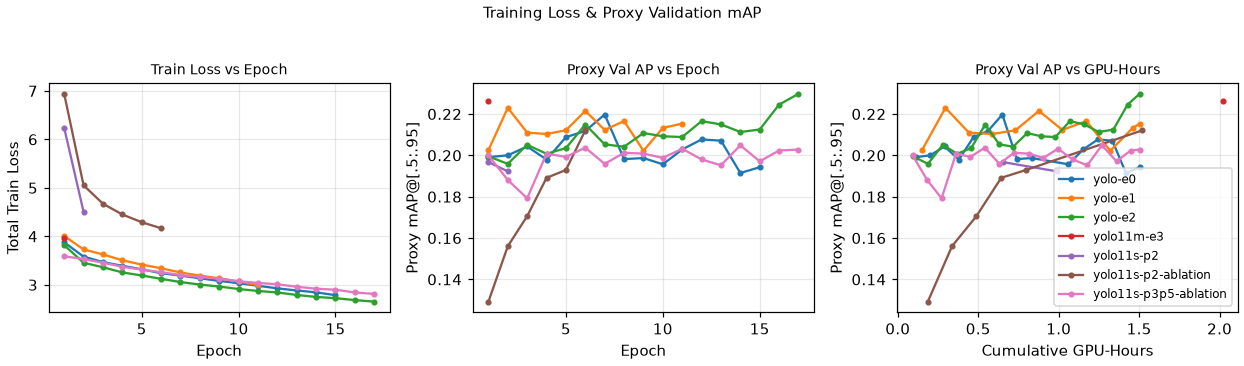

In [7]:
yolo_runs = ["yolo-e0", "yolo-e1", "yolo-e2", "yolo11m-e3", "yolo11s-p2"]
display(results_table(run_ids=yolo_runs))
cls_cols = ["run_id"] + [f"ap_{c}" for c in ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]]
display(results_table(run_ids=yolo_runs, cols=cls_cols).round(3))
show_image("curves_yolo.png", 850)

**Notes.** 1600 px: +0.012 AP, AP_small 0.108 → 0.131, 56 → 33 FPS. NWD: no gain (0.2021). `yolo11s-p2` is not a valid test of the P2 head (several changes at once, stopped during LR warm-up); see 04b.